In [12]:
import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
from scipy.ndimage import label, generate_binary_structure
from tqdm import tqdm

# --- Configuration ---
DATA_DIR = "./data" if os.path.exists("./data") else "../data"
CURIE_DIR = os.path.join(DATA_DIR, "PET-EARL", "curie")
EXCEL_PATH = os.path.join(DATA_DIR, "FEDERATEDPET_V3.0_CURIE.xlsx")

SUV_CLIP = 4.0       # Drop à la volée des voxels < 4.0 SUV dans chaque composante (en mémoire)
MIN_VOXELS = 10      # Taille min d'une composante après clip (filtre les micro-artefacts)
T0_COL = "Date du premier cycle de traitement"
STRUCT_3D = generate_binary_structure(3, 3)

# --- 1. Données cliniques (Excel Curie) ---
df_clin = pd.read_excel(EXCEL_PATH, sheet_name="DB", header=2, dtype={"Numero patient": str})
df_clin["patient_id"] = df_clin["Numero patient"].str.strip().str.zfill(5)
df_clin["histology"] = df_clin["Type histologique du cancer du poumon non à petites cellules"].str.strip()
df_clin["event"] = (df_clin["Statut vital"].str.strip() == "DECES").astype(int)

for col in [T0_COL, "Date de dernières nouvelles", "Date du décès"]:
    df_clin[col] = pd.to_datetime(df_clin[col], errors="coerce")

end_date = df_clin["Date du décès"].where(df_clin["event"] == 1, df_clin["Date de dernières nouvelles"])
df_clin["os_months"] = (end_date - df_clin[T0_COL]).dt.days / 30.4375

# --- 2. Extraction rapide par composantes connexes (crop bbox + clip < 4.0 SUV à la volée) ---
def extract_by_components(img_box, labeled_box, n_comp, voxel_vol_ml):
    suvmax_list, suvmean_list, mtv_list, tlg_list = [], [], [], []
    for comp_id in range(1, n_comp + 1):
        vals = img_box[(labeled_box == comp_id) & (img_box >= SUV_CLIP)]
        if len(vals) < MIN_VOXELS:
            continue
        # TODO: ajouter SUVpeak par composante ici
        suvmax_list.append(float(np.max(vals)))
        suvmean_list.append(float(np.mean(vals)))
        mtv_comp = float(len(vals) * voxel_vol_ml)
        mtv_list.append(mtv_comp)
        tlg_list.append(float(np.sum(vals) * voxel_vol_ml))

    if not suvmax_list:
        return np.nan, np.nan, np.nan, np.nan, 0
    hottest_idx = int(np.argmax(suvmax_list))
    return (
        suvmax_list[hottest_idx],        # SUVmax de la lésion la plus intense
        float(np.mean(suvmean_list)),    # SUVmean moyen sur l'ensemble des lésions
        float(np.sum(mtv_list)),         # TMTV total patient (mL)
        float(np.sum(tlg_list)),         # TLG total patient
        len(suvmax_list),
    )

rows = []
for pid in tqdm(sorted(os.listdir(CURIE_DIR)), desc="Extraction SUV par composante"):
    pdir = os.path.join(CURIE_DIR, pid)
    mask_path = os.path.join(pdir, "lesion.nii.gz")
    pet_path = os.path.join(pdir, "PET.nii.gz")
    harm_path = os.path.join(pdir, "harmonized-pet-gaussian.nii.gz")
    if not (os.path.isdir(pdir) and os.path.exists(mask_path) and os.path.exists(pet_path) and os.path.exists(harm_path)):
        continue

    mask_arr = sitk.GetArrayFromImage(sitk.ReadImage(mask_path)) > 0
    if not np.any(mask_arr):
        continue

    pet_sitk = sitk.ReadImage(pet_path)
    voxel_vol_ml = float(np.prod(pet_sitk.GetSpacing())) / 1000.0
    pet_arr = sitk.GetArrayFromImage(pet_sitk)
    harm_arr = sitk.GetArrayFromImage(sitk.ReadImage(harm_path))

    # Bounding box serrée autour du masque pour accélérer label() (~100x plus rapide)
    z, y, x = np.where(mask_arr)
    bbox = (slice(z.min(), z.max() + 1), slice(y.min(), y.max() + 1), slice(x.min(), x.max() + 1))
    labeled_box, n_comp = label(mask_arr[bbox], structure=STRUCT_3D)

    smax_p, smean_p, tmtv_p, tlg_p, n_p = extract_by_components(pet_arr[bbox], labeled_box, n_comp, voxel_vol_ml)
    smax_h, smean_h, tmtv_h, tlg_h, n_h = extract_by_components(harm_arr[bbox], labeled_box, n_comp, voxel_vol_ml)
    rows.append({
        "patient_id": pid.zfill(5),
        "suvmax_pet": smax_p, "suvmean_pet": smean_p, "tmtv_pet": tmtv_p, "tlg_pet": tlg_p, "n_comp_pet": n_p,
        "suvmax_harm": smax_h, "suvmean_harm": smean_h, "tmtv_harm": tmtv_h, "tlg_harm": tlg_h, "n_comp_harm": n_h,
    })

df_curie = pd.DataFrame(rows).merge(
    df_clin[["patient_id", "histology", "event", "os_months"]],
    on="patient_id", how="inner"
)
print(f"Patients: {len(df_curie)} | Décès: {df_curie['event'].sum()} | Expirés après clip/min_vox (Harm): {df_curie['suvmax_harm'].isna().sum()}")


Extraction SUV par composante: 100%|██████████| 81/81 [03:36<00:00,  2.67s/it]

Patients: 81 | Décès: 55 | Expirés après clip/min_vox (Harm): 0


/home/aghiles/anaconda3/envs/work_p11/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/home/aghiles/anaconda3/envs/work_p11/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/home/aghiles/anaconda3/envs/work_p11/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/home/aghiles/anaconda3/envs/work_p11/lib/python3.11/sit

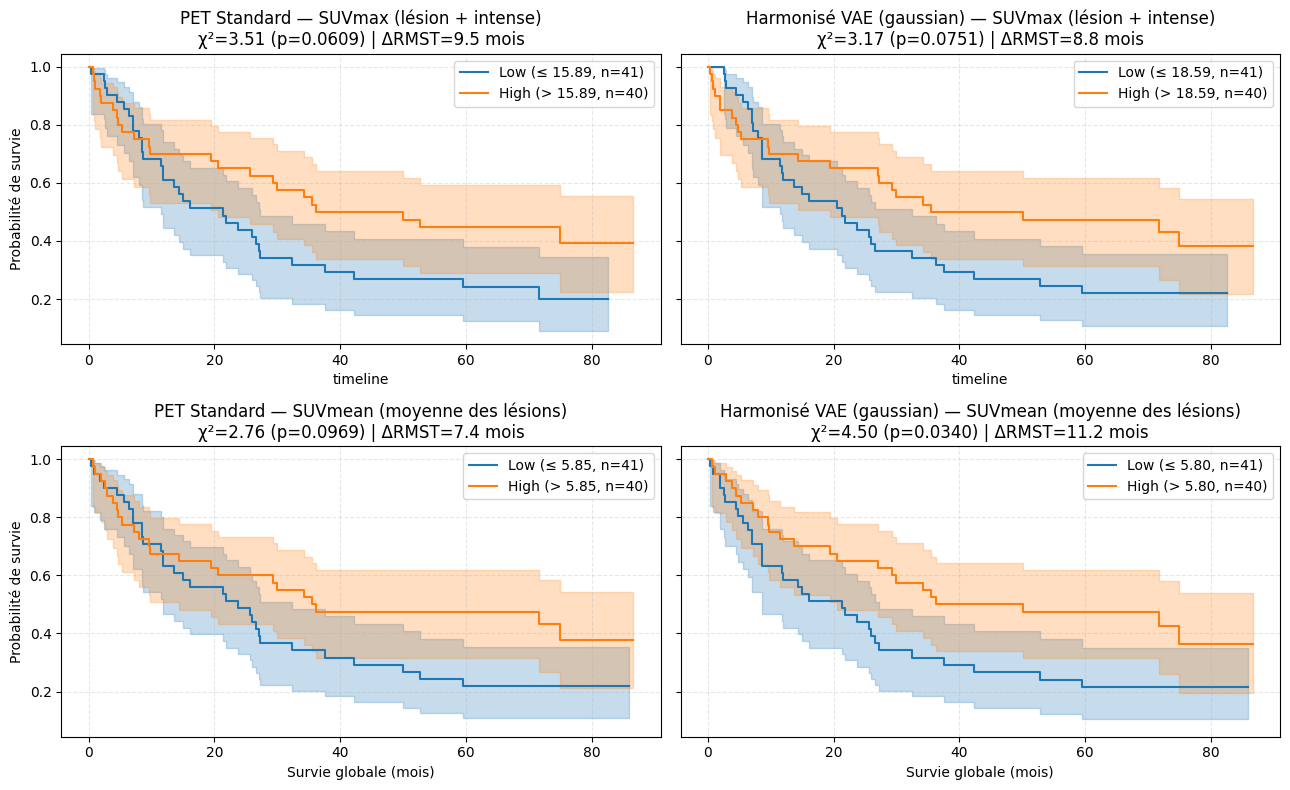

In [13]:
# --- Affichage multi-métriques directement depuis df_curie en mémoire ---
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import restricted_mean_survival_time

RMST_HORIZON = 60.0  # Horizon (mois) pour quantifier la distance ΔRMST entre courbes KM
metrics_to_plot = [
    ("suvmax", "SUVmax (lésion + intense)"),
    ("suvmean", "SUVmean (moyenne des lésions)"),
]

fig, axes = plt.subplots(len(metrics_to_plot), 2, figsize=(13, 4 * len(metrics_to_plot)), sharey=True, squeeze=False)
for r, (m_key, m_label) in enumerate(metrics_to_plot):
    for c, (suffix, mod_title) in enumerate([("pet", "PET Standard"), ("harm", "Harmonisé VAE (gaussian)")]):
        ax = axes[r, c]
        col = f"{m_key}_{suffix}"
        sub = df_curie.dropna(subset=[col, "os_months", "event"])
        med = sub[col].median()
        low, high = sub[sub[col] <= med], sub[sub[col] > med]

        lr = logrank_test(low["os_months"], high["os_months"], event_observed_A=low["event"], event_observed_B=high["event"])
        kmf_low = KaplanMeierFitter().fit(low["os_months"], event_observed=low["event"], label=f"Low (≤ {med:.2f}, n={len(low)})")
        kmf_high = KaplanMeierFitter().fit(high["os_months"], event_observed=high["event"], label=f"High (> {med:.2f}, n={len(high)})")

        kmf_low.plot_survival_function(ax=ax, ci_show=True)
        kmf_high.plot_survival_function(ax=ax, ci_show=True)

        rmst_diff = abs(restricted_mean_survival_time(kmf_low, t=RMST_HORIZON) - restricted_mean_survival_time(kmf_high, t=RMST_HORIZON))
        ax.set_title(f"{mod_title} — {m_label}\nχ²={lr.test_statistic:.2f} (p={lr.p_value:.4f}) | ΔRMST={rmst_diff:.1f} mois")
        ax.grid(alpha=0.3, linestyle="--")
        if r == len(metrics_to_plot) - 1:
            ax.set_xlabel("Survie globale (mois)")
    axes[r, 0].set_ylabel("Probabilité de survie")

plt.tight_layout()
plt.show()
